Célula 1 – setup:

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from src.utils import set_seed, SEED, CLASS_NAMES, get_splits, train_and_evaluate_classifier

set_seed()
X_train, y_train, X_val, y_val, X_test, y_test = get_splits()

Célula 2 – treinar e avaliar:

In [2]:
clf_raw, acc_raw, t_raw = train_and_evaluate_classifier(X_train, y_train, X_val, y_val)
print(f"Pixels brutos (784 dim) -> accuracy validação = {acc_raw:.4f} | treino em {t_raw:.1f} s")

pd.DataFrame([{"space": "raw pixels", "dim": 784, "val_accuracy": acc_raw, "train_time_s": t_raw}]) \
  .to_csv("results/tables/03_baseline_raw.csv", index=False)

Pixels brutos (784 dim) -> accuracy validação = 0.8559 | treino em 820.4 s


Célula 3 – accuracy por classe:

In [3]:
y_pred_val = clf_raw.predict(X_val)
print(classification_report(y_val, y_pred_val, target_names=CLASS_NAMES, digits=3))

              precision    recall  f1-score   support

 T-shirt/top      0.806     0.839     0.822      1000
     Trouser      0.963     0.968     0.966      1000
    Pullover      0.765     0.764     0.764      1000
       Dress      0.866     0.855     0.861      1000
        Coat      0.762     0.778     0.770      1000
      Sandal      0.939     0.932     0.935      1000
       Shirt      0.655     0.617     0.635      1000
     Sneaker      0.922     0.936     0.929      1000
         Bag      0.932     0.925     0.928      1000
  Ankle boot      0.941     0.945     0.943      1000

    accuracy                          0.856     10000
   macro avg      0.855     0.856     0.855     10000
weighted avg      0.855     0.856     0.855     10000



Célula 4 – matriz de confusão:

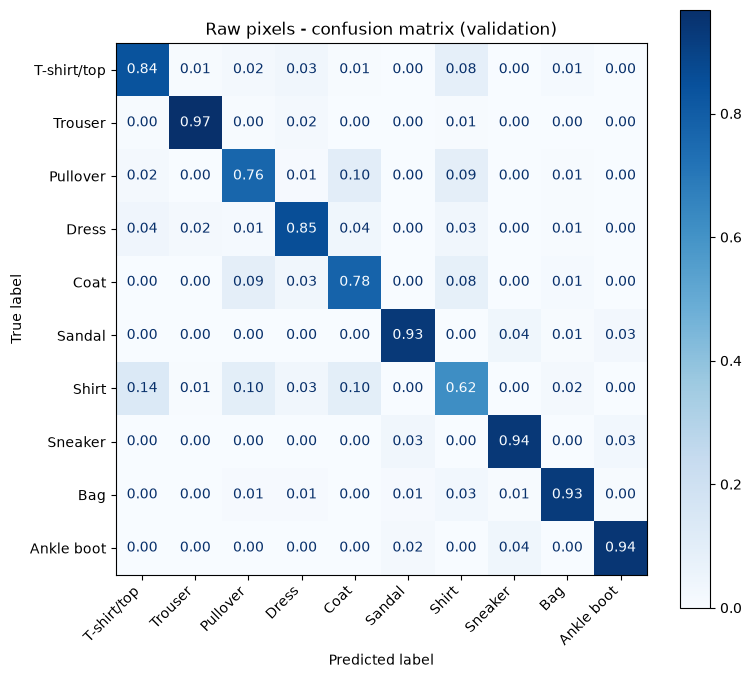

In [4]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred_val,
    display_labels=CLASS_NAMES,
    normalize="true",         
    values_format=".2f",
    cmap="Blues",
    ax=ax,
)
plt.xticks(rotation=45, ha="right")
plt.title("Raw pixels - confusion matrix (validation)")
plt.tight_layout()
plt.savefig("results/figures/03_confusion_raw_pixels.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
import joblib

joblib.dump(clf_raw, "models/clf_raw.joblib")        
print("Iterações usadas:", clf_raw[-1].n_iter_)       

Iterações usadas: [980]
